# Sentiment Analysis Using Traditional Machine Learning 
## PUSL 3205 - LLM AND Generative AI
## Topic: Text Preprocessing, TF-IDF and Machine Learning 
## Objectives
#### Perform basic text preprocessing techniques on text data.
#### Explore positive and negative sentiment patterns in reviews.
#### Convert text data into numerical representations using Bag of Words and TF-IDF.
#### Train machine learning models for sentiment classification.
#### Evaluate models using Accuracy, Precision, Recall and F1-score.
#### Test trained models on new, manually created sentences.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


## 1. Dataset load

In [5]:
import os
import pandas as pd

dataset_path = r"C:\Users\yehan\OneDrive - University of Plymouth\Documents\LLM AND GENERATIVE AI\data sets"

files = [
    "amazon_cells_labelled.txt",
    "imdb_labelled.txt",
    "yelp_labelled.txt"
]

dataframes = []

for file in files:
    df = pd.read_csv(
        os.path.join(dataset_path, file),
        sep="\t",
        header=None,
        names=["text", "sentiment"]
    )

    dataframes.append(df)

data = pd.concat(dataframes, ignore_index=True)

print("Dataset loaded")
print("Dataset shape:", data.shape)

data.head()

Dataset loaded
Dataset shape: (2748, 2)


,text,sentiment
0,So there is no way for me to plug it in here i...,0
1,"Good case, Excellent value.",1
2,Great for the jawbone.,1
3,Tied to charger for conversations lasting more...,0
4,The mic is great.,1


In [7]:
import re
print("done")

done


## 2. Perform basic text preprocessing
### o Convert text to lowercase, Remove unnecessary characters and punctuation, Remove extra whitespace. 

In [8]:
def preprocess_text(text):
    text = text.lower()

    # Remove unnecessary characters and punctuation,
    text = re.sub(r'[^a-z\s]', '', text)

    # Remove extra whitespace
    text = re.sub(r'\s+', ' ', text).strip()

    return text

### o Create a clean-text column.  

In [9]:
data["clean_text"] = data["text"].apply(preprocess_text)

print("Text preprocessing completed")

data.head()

Text preprocessing completed


,text,sentiment,clean_text
0,So there is no way for me to plug it in here i...,0,so there is no way for me to plug it in here i...
1,"Good case, Excellent value.",1,good case excellent value
2,Great for the jawbone.,1,great for the jawbone
3,Tied to charger for conversations lasting more...,0,tied to charger for conversations lasting more...
4,The mic is great.,1,the mic is great


### o Compare original and preprocessed text. 

In [11]:
comparison = data[["text", "clean_text", "sentiment"]].head(20)

comparison

,text,clean_text,sentiment
0,So there is no way for me to plug it in here i...,so there is no way for me to plug it in here i...,0
1,"Good case, Excellent value.",good case excellent value,1
2,Great for the jawbone.,great for the jawbone,1
3,Tied to charger for conversations lasting more...,tied to charger for conversations lasting more...,0
4,The mic is great.,the mic is great,1
5,I have to jiggle the plug to get it to line up...,i have to jiggle the plug to get it to line up...,0
6,If you have several dozen or several hundred c...,if you have several dozen or several hundred c...,0
7,If you are Razr owner...you must have this!,if you are razr owneryou must have this,1
8,"Needless to say, I wasted my money.",needless to say i wasted my money,0
9,What a waste of money and time!.,what a waste of money and time,0


## 3. Explore the text data 
### o Display positive and negative examples.  

In [13]:
data["sentiment"].value_counts()

sentiment
1    1386
0    1362
Name: count, dtype: int64

In [16]:
positive_reviews = data[data["sentiment"] == 1]

positive_reviews[["text", "clean_text"]].head()

,text,clean_text
1,"Good case, Excellent value.",good case excellent value
2,Great for the jawbone.,great for the jawbone
4,The mic is great.,the mic is great
7,If you are Razr owner...you must have this!,if you are razr owneryou must have this
10,And the sound quality is great.,and the sound quality is great


In [15]:
negative_reviews = data[data["sentiment"] == 0]

negative_reviews[["text", "clean_text"]].head()

,text,clean_text
0,So there is no way for me to plug it in here i...,so there is no way for me to plug it in here i...
3,Tied to charger for conversations lasting more...,tied to charger for conversations lasting more...
5,I have to jiggle the plug to get it to line up...,i have to jiggle the plug to get it to line up...
6,If you have several dozen or several hundred c...,if you have several dozen or several hundred c...
8,"Needless to say, I wasted my money.",needless to say i wasted my money


### o Identify frequently occurring words.  
###### ( remove common english words like the, is, and, a, of, etc.)

In [17]:
from collections import Counter
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

stop_words = set(ENGLISH_STOP_WORDS)

print("Stopwords loaded:", len(stop_words))

Stopwords loaded: 318


##### Calculate the most frequent words

In [19]:
all_words = " ".join(data["clean_text"])

words = all_words.split()

filtered_words = [word for word in words if word not in stop_words]

word_counts = Counter(filtered_words)

most_common_words = word_counts.most_common()

most_common_words

[('good', 228),
 ('great', 207),
 ('movie', 177),
 ('phone', 162),
 ('film', 155),
 ('food', 124),
 ('like', 123),
 ('just', 119),
 ('place', 114),
 ('time', 111),
 ('service', 106),
 ('really', 103),
 ('bad', 99),
 ('dont', 85),
 ('best', 78),
 ('quality', 65),
 ('love', 61),
 ('ive', 60),
 ('product', 56),
 ('im', 56),
 ('work', 54),
 ('works', 53),
 ('nice', 53),
 ('better', 53),
 ('excellent', 52),
 ('recommend', 50),
 ('use', 49),
 ('did', 49),
 ('sound', 48),
 ('headset', 47),
 ('think', 47),
 ('battery', 45),
 ('way', 44),
 ('didnt', 42),
 ('make', 42),
 ('pretty', 41),
 ('acting', 41),
 ('got', 39),
 ('worst', 39),
 ('does', 37),
 ('say', 36),
 ('characters', 36),
 ('ear', 35),
 ('little', 35),
 ('disappointed', 35),
 ('thing', 34),
 ('price', 34),
 ('right', 33),
 ('waste', 33),
 ('going', 33),
 ('people', 33),
 ('case', 32),
 ('definitely', 32),
 ('minutes', 32),
 ('real', 32),
 ('terrible', 32),
 ('amazing', 32),
 ('money', 31),
 ('look', 31),
 ('movies', 31),
 ('new', 30),


##### Visualize the most frequent words

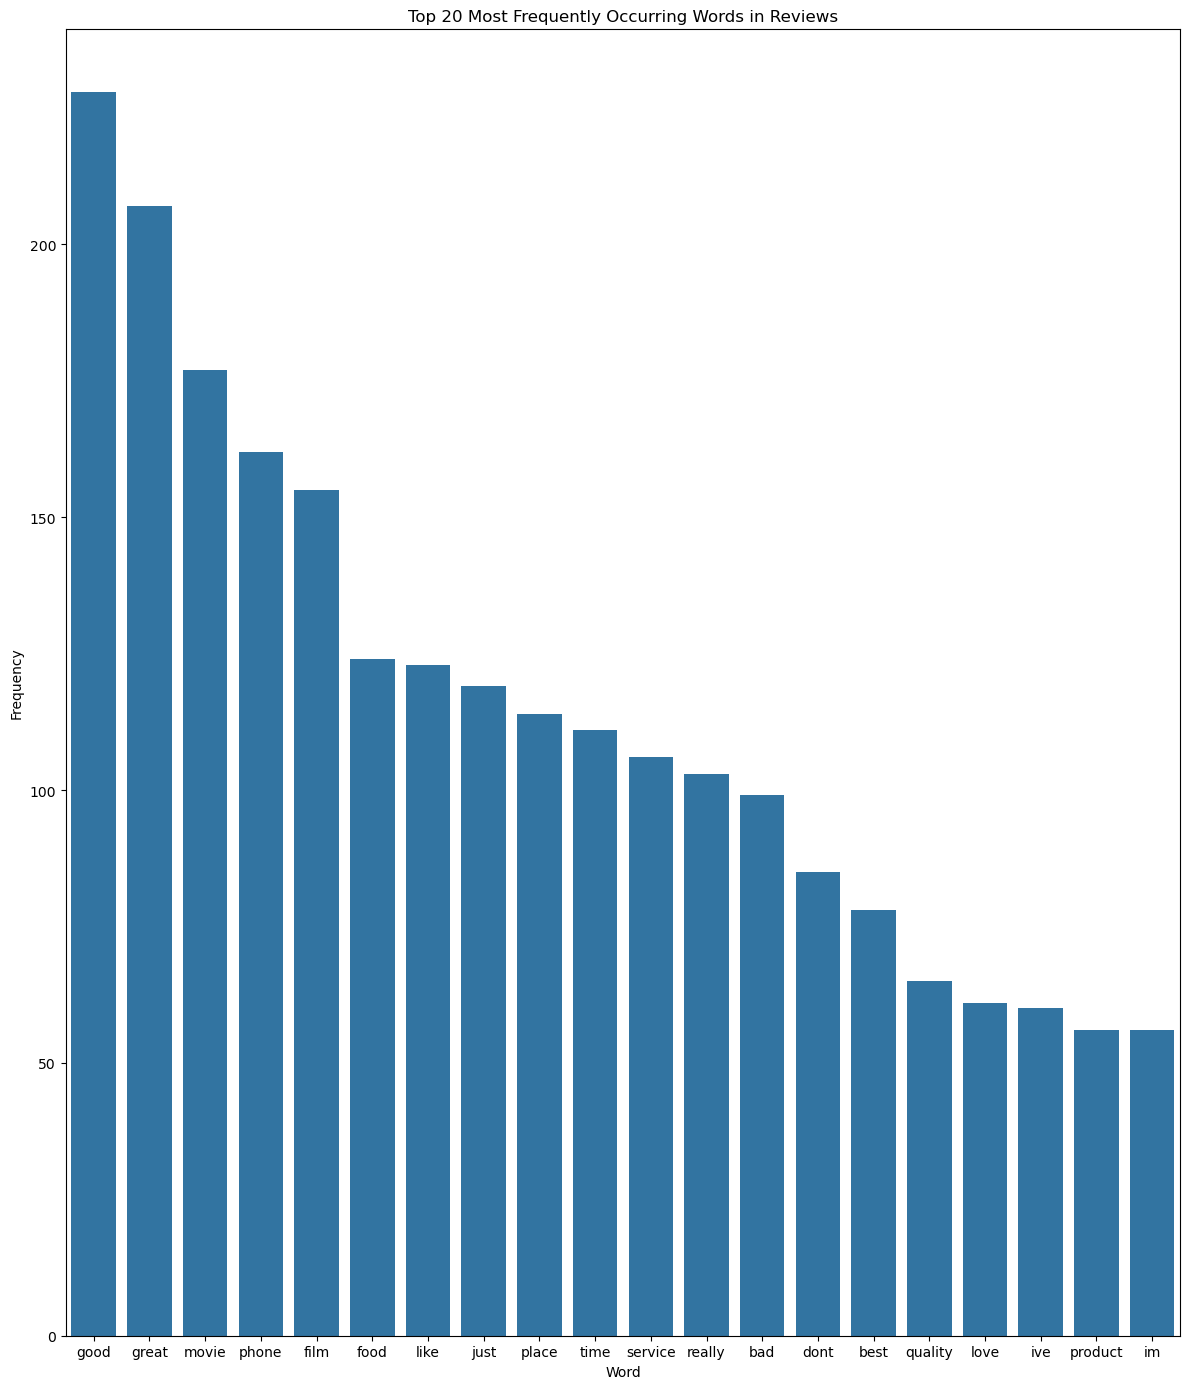

In [23]:
word_freq_df = pd.DataFrame(
    word_counts.most_common(20),
    columns=["Word", "Frequency"]
)

plt.figure(figsize=(12, 14))

sns.barplot(
    data=word_freq_df,
    y="Frequency",
    x="Word"
)

plt.title("Top 20 Most Frequently Occurring Words in Reviews")
plt.ylabel("Frequency")
plt.xlabel("Word")
plt.tight_layout()
plt.show()

In [22]:
print(word_counts.most_common(10))

[('good', 228), ('great', 207), ('movie', 177), ('phone', 162), ('film', 155), ('food', 124), ('like', 123), ('just', 119), ('place', 114), ('time', 111)]


### o Observe differences between positive and negative reviews. 

In [24]:
positive_text = " ".join(positive_reviews["clean_text"])

positive_words = positive_text.split()

positive_filtered_words = [
    word for word in positive_words
    if word not in stop_words
]

positive_word_counts = Counter(positive_filtered_words)

positive_word_counts.most_common(15)

[('great', 190),
 ('good', 172),
 ('phone', 86),
 ('movie', 84),
 ('film', 84),
 ('really', 60),
 ('food', 60),
 ('best', 59),
 ('like', 58),
 ('place', 58),
 ('service', 54),
 ('love', 51),
 ('just', 50),
 ('time', 50),
 ('works', 49)]

In [25]:
negative_text = " ".join(negative_reviews["clean_text"])

negative_words = negative_text.split()

negative_filtered_words = [
    word for word in negative_words
    if word not in stop_words
]

negative_word_counts = Counter(negative_filtered_words)

negative_word_counts.most_common(15)

[('movie', 93),
 ('bad', 92),
 ('phone', 76),
 ('film', 71),
 ('just', 69),
 ('dont', 66),
 ('like', 65),
 ('food', 64),
 ('time', 61),
 ('place', 56),
 ('good', 56),
 ('service', 52),
 ('really', 43),
 ('work', 39),
 ('worst', 38)]

##### visualize negative and positive word frequencies

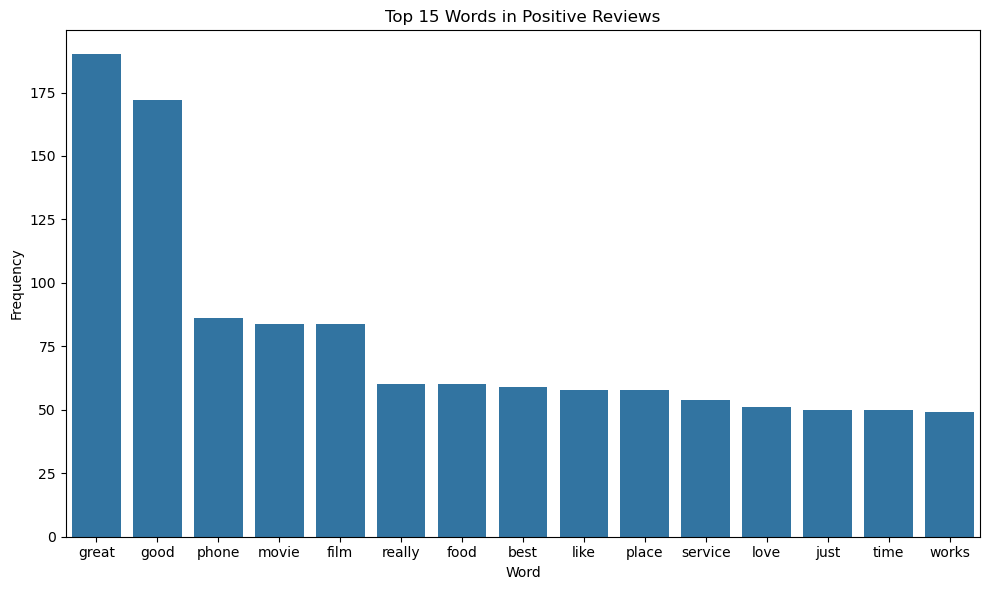

In [27]:
positive_freq_df = pd.DataFrame(
    positive_word_counts.most_common(15),
    columns=["Word", "Frequency"]
)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=positive_freq_df,
    x="Word",
    y="Frequency"
    
)

plt.title("Top 15 Words in Positive Reviews")
plt.ylabel("Frequency")
plt.xlabel("Word")
plt.tight_layout()
plt.show()

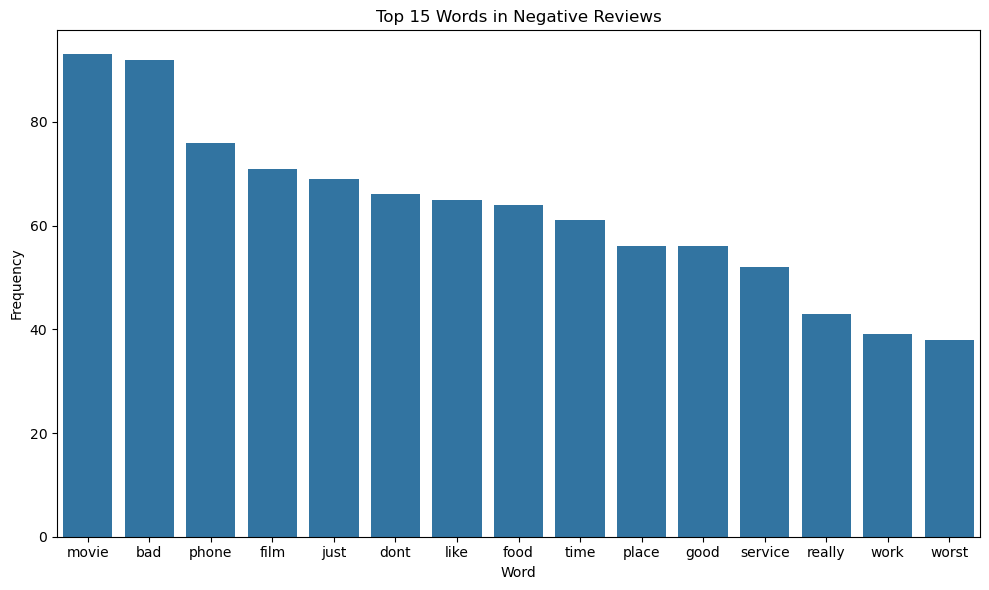

In [28]:
negative_freq_df = pd.DataFrame(
    negative_word_counts.most_common(15),
    columns=["Word", "Frequency"]
)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=negative_freq_df,
    y="Frequency",
    x="Word"
)

plt.title("Top 15 Words in Negative Reviews")
plt.ylabel("Frequency")
plt.xlabel("Word")
plt.tight_layout()
plt.show()

 ### Observation

##### In my study, I looked at how words appear in **positive reviews** and compared that to how often they appear in **negative reviews**. **Positive reviews** often contain words such as *great*, *good*, *best* and *love*, which show feelings. On the hand, **negative reviews** often contain words like *bad* and *worst*, which show unhappiness. Words such as *film*, *phone*, *food*, *movie* and *service* appear in both **reviews**. **Negative reviews** because they talk about topics, not feelings.
##### These findings show that **frequency** can give clues about the feelings people express in writing. Simply counting words does not always reveal the meaning. For example, a negation such as 'do not' can flip the meaning of a sentence. Also, when I cleaned the data by taking away punctuation or apostrophes, I might have changed how the original text looked.

### 4. Split the dataset 

In [29]:
from sklearn.model_selection import train_test_split

X = data["clean_text"]
y = data["sentiment"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 2198
Testing samples: 550


### 5. Create BOW representation

In [30]:
from sklearn.feature_extraction.text import CountVectorizer

##### create the bag of words (BOW ) representation

In [31]:
bow_vectorizer = CountVectorizer()

X_train_bow = bow_vectorizer.fit_transform(X_train)
X_test_bow = bow_vectorizer.transform(X_test)

print("Training BOW shape:", X_train_bow.shape)
print("Testing BOW shape:", X_test_bow.shape)

Training BOW shape: (2198, 4611)
Testing BOW shape: (550, 4611)


##### examine the vocabulary 

In [37]:
vocabulary = bow_vectorizer.get_feature_names_out()

print("Total vocabulary size:", len(vocabulary))
print("\nFirst 30 words in vocabulary:")
print(vocabulary[:30])

Total vocabulary size: 4611

First 30 words in vocabulary:
['aailiyah' 'abandoned' 'abhor' 'ability' 'able' 'abound' 'about' 'above'
 'abovepretty' 'abroad' 'absolute' 'absolutel' 'absolutely' 'absolutley'
 'abstruse' 'abysmal' 'academy' 'accept' 'acceptable' 'access'
 'accessable' 'accessible' 'accessing' 'accessory' 'accessoryone'
 'accident' 'accolades' 'accommodations' 'accomodate' 'accompanied']


##### view the numerical representation

In [40]:
bow_sample = pd.DataFrame(
    X_train_bow[:10].toarray(),
    columns=bow_vectorizer.get_feature_names_out()
)

bow_sample

,aailiyah,abandoned,abhor,ability,able,abound,about,above,abovepretty,abroad,...,yukon,yum,yummy,yun,za,zero,zillion,zombie,zombiestudents,zombiez
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
5,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
6,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
7,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
8,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
9,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


##### visualie the word counts for a sample review

In [42]:
sample_vector = X_train_bow[0].toarray().flatten()

sample_word_counts = pd.DataFrame({
    "Word": bow_vectorizer.get_feature_names_out(),
    "Count": sample_vector})

sample_word_counts = sample_word_counts[
    sample_word_counts["Count"] > 0
].sort_values(by="Count", ascending=False)

sample_word_counts

,Word,Count
4017,the,4
210,as,2
99,all,1
2082,interplay,1
4459,well,1
4417,was,1
4048,this,1
3925,surrounding,1
3891,suggest,1
3694,some,1


### 6. Train a ML model (SVM, Logistic Regression etc...)

In [44]:
from sklearn.linear_model import LogisticRegression

In [46]:
from sklearn.feature_extraction.text import TfidfVectorizer

In [47]:
tfidf_vectorizer = TfidfVectorizer()

X_train_tfidf = tfidf_vectorizer.fit_transform(X_train)
X_test_tfidf = tfidf_vectorizer.transform(X_test)

print("Training TF-IDF shape:", X_train_tfidf.shape)
print("Testing TF-IDF shape:", X_test_tfidf.shape)

Training TF-IDF shape: (2198, 4611)
Testing TF-IDF shape: (550, 4611)


In [48]:
from sklearn.linear_model import LogisticRegression

model_tfidf = LogisticRegression(max_iter=1000)

model_tfidf.fit(X_train_tfidf, y_train)

print("TF-IDF model trained")

TF-IDF model trained


##### train the bow model

In [49]:
model_bow = LogisticRegression(max_iter=1000)

model_bow.fit(X_train_bow, y_train)

print("BOW model trained")

BOW model trained


##### SVM model train using TF-IDF

In [54]:
from sklearn.svm import LinearSVC

model_svm = LinearSVC()
model_svm.fit(X_train_tfidf, y_train)

,penalty,'l2'
,loss,'squared_hinge'
,dual,'auto'
,tol,0.0001
,C,1.0
,multi_class,'ovr'
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,verbose,0
,random_state,None


### 7. Evaluate the model’s performance. (Accuracy, Precision, Recall, F1) 

In [55]:
y_pred_bow = model_bow.predict(X_test_bow)

y_pred_tfidf = model_tfidf.predict(X_test_tfidf)

y_pred_svm = model_svm.predict(X_test_tfidf)

calculate the evaluation metrics

In [56]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Evaluate BOW + Logistic Regression
bow_metrics = [
    accuracy_score(y_test, y_pred_bow),
    precision_score(y_test, y_pred_bow),
    recall_score(y_test, y_pred_bow),
    f1_score(y_test, y_pred_bow)
]

# Evaluate TF-IDF + Logistic Regression
tfidf_metrics = [
    accuracy_score(y_test, y_pred_tfidf),
    precision_score(y_test, y_pred_tfidf),
    recall_score(y_test, y_pred_tfidf),
    f1_score(y_test, y_pred_tfidf)
]

# Evaluate TF-IDF + SVM
svm_metrics = [
    accuracy_score(y_test, y_pred_svm),
    precision_score(y_test, y_pred_svm),
    recall_score(y_test, y_pred_svm),
    f1_score(y_test, y_pred_svm)
]

print("BOW + Logistic Regression:", bow_metrics)
print("TF-IDF + Logistic Regression:", tfidf_metrics)
print("TF-IDF + SVM:", svm_metrics)

BOW + Logistic Regression: [0.8109090909090909, 0.8239700374531835, 0.7942238267148014, 0.8088235294117647]
TF-IDF + Logistic Regression: [0.8145454545454546, 0.8326996197718631, 0.7906137184115524, 0.8111111111111111]
TF-IDF + SVM: [0.8254545454545454, 0.8220640569395018, 0.8339350180505415, 0.8279569892473119]


##### visual comparison chart

In [57]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

results_df = pd.DataFrame({
    "Model": [
        "BOW + Logistic Regression",
        "TF-IDF + Logistic Regression",
        "TF-IDF + SVM"
    ],
    "Accuracy": [
        accuracy_score(y_test, y_pred_bow),
        accuracy_score(y_test, y_pred_tfidf),
        accuracy_score(y_test, y_pred_svm)
    ],
    "Precision": [
        precision_score(y_test, y_pred_bow),
        precision_score(y_test, y_pred_tfidf),
        precision_score(y_test, y_pred_svm)
    ],
    "Recall": [
        recall_score(y_test, y_pred_bow),
        recall_score(y_test, y_pred_tfidf),
        recall_score(y_test, y_pred_svm)
    ],
    "F1-score": [
        f1_score(y_test, y_pred_bow),
        f1_score(y_test, y_pred_tfidf),
        f1_score(y_test, y_pred_svm)
    ]
})

results_df

,Model,Accuracy,Precision,Recall,F1-score
0,BOW + Logistic Regression,0.810909,0.823970,0.794224,0.808824
1,TF-IDF + Logistic Regression,0.814545,0.832700,0.790614,0.811111
2,TF-IDF + SVM,0.825455,0.822064,0.833935,0.827957


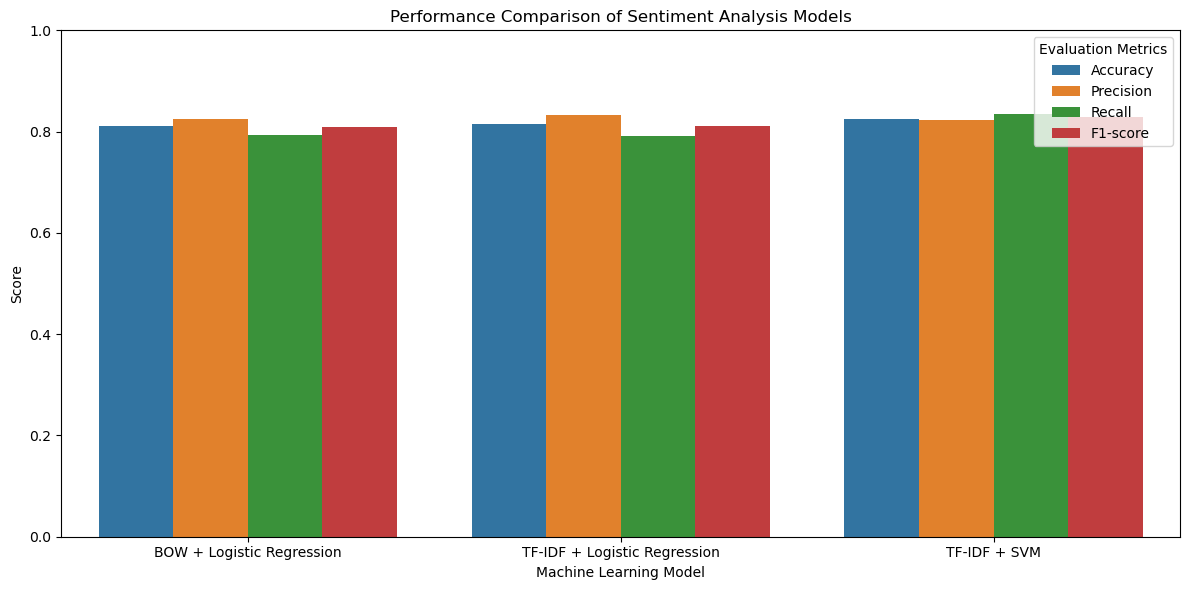

In [62]:
plt.figure(figsize=(12, 6))

results_melted = results_df.melt(
    id_vars="Model",
    var_name="Metric",
    value_name="Score"
)

sns.barplot(
    data=results_melted,
    x="Model",
    y="Score",
    hue="Metric"
)

plt.title("Performance Comparison of Sentiment Analysis Models")
plt.ylabel("Score")
plt.xlabel("Machine Learning Model")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(title="Evaluation Metrics")
plt.tight_layout()
plt.show()

### 8. Test the model with new sentence.
##### create new sentences

In [63]:
new_sentences = [
    "Honestly, I did not expect much but this turned out to be one of my favourite purchases",
    "I waited so long for this and it was honestly such a letdown",
    "The staff were friendly and made the whole experience feel really pleasant",
    "It stopped working after just a few days and I am so frustrated",
    "It is not perfect, but I think it is worth the money I spent"
]

In [64]:
# Preprocess the new sentences
cleaned_sentences = [preprocess_text(sentence) for sentence in new_sentences]

# Convert into TF-IDF features
new_sentences_tfidf = tfidf_vectorizer.transform(cleaned_sentences)

# Predict using the trained SVM model
new_predictions = model_svm.predict(new_sentences_tfidf)

# Display results
prediction_results = pd.DataFrame({
    "Original Sentence": new_sentences,
    "Predicted Sentiment": [
        "Positive" if prediction == 1 else "Negative"
        for prediction in new_predictions
    ]
})

prediction_results

,Original Sentence,Predicted Sentiment
0,"Honestly, I did not expect much but this turne...",Negative
1,I waited so long for this and it was honestly ...,Negative
2,The staff were friendly and made the whole exp...,Positive
3,It stopped working after just a few days and I...,Positive
4,"It is not perfect, but I think it is worth the...",Negative


### Observation of new sentences prediction
##### The SVM model that was trained was evaluated using five manually created sentences. These statements used informal language. The model successfully classified two of the five sentences. It accurately identified the sentiment in the second sentence. It accurately recognized the sentiment in the third sentence. The model incorrectly identified the first, fourth, and fifth sentences. The errors indicate that the model may struggle with grasping context. It also has difficulty with negation and opposing ideas. The sentences were crafted by hand. The quantity of examples was quite limited. This indicates that the outcomes do not provide a trustworthy depiction of the model's overall effectiveness. Nonetheless, this experiment indicates that conventional machine learning models may struggle with language that is intricate or heavily reliant on context.
